# 02 - Exploratory Data Analysis

Explores the cleaned dataset produced by `01_cleaning.ipynb` (`data/processed/cleaned_employee_attrition.csv`). Focus: understand attrition drivers to inform feature engineering and the charts shown on the dashboard.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

df = pd.read_csv('../data/processed/cleaned_employee_attrition.csv')
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(1470, 33)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,0


## Overall Attrition Rate

Overall attrition rate: 16.1%


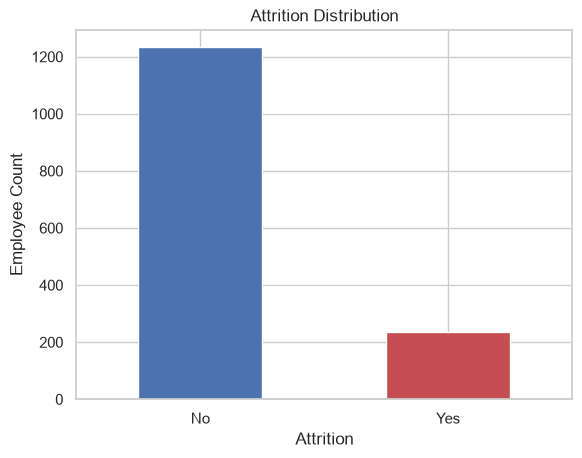

In [2]:
attrition_rate = df['Attrition_Flag'].mean()
print(f"Overall attrition rate: {attrition_rate:.1%}")

ax = df['Attrition'].value_counts().plot(kind='bar', color=['#4C72B0', '#C44E52'])
ax.set_title('Attrition Distribution')
ax.set_xlabel('Attrition')
ax.set_ylabel('Employee Count')
plt.xticks(rotation=0)
plt.show()

## Numerical Feature Distributions by Attrition

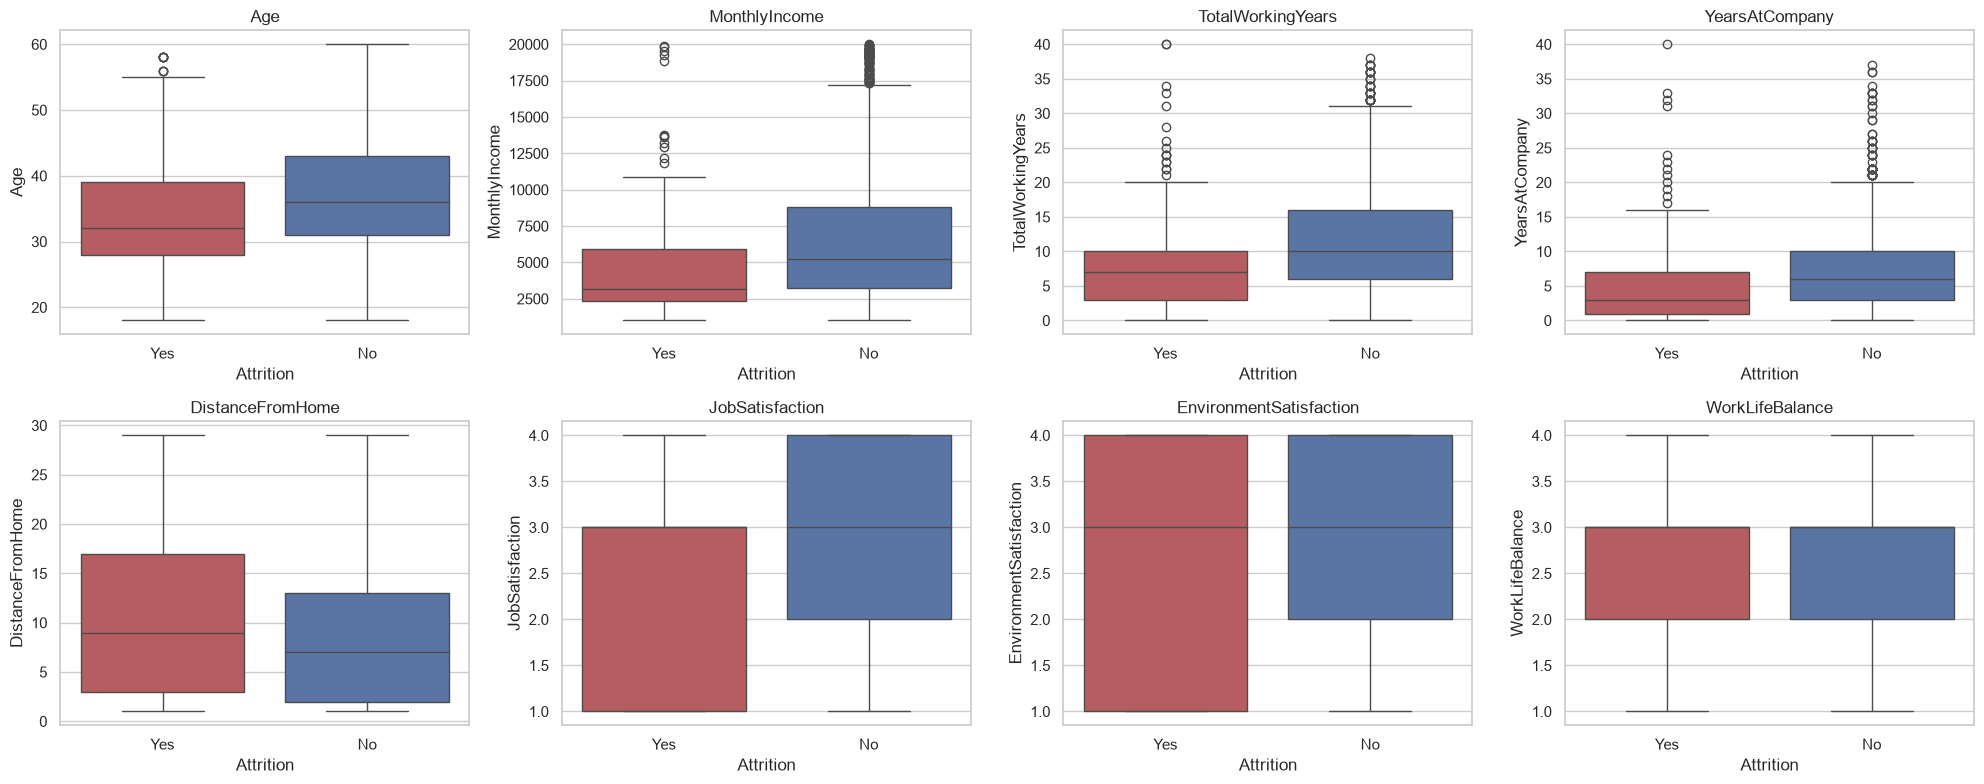

In [3]:
key_numerical = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                  'DistanceFromHome', 'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, key_numerical):
    sns.boxplot(data=df, x='Attrition', y=col, ax=ax, hue='Attrition', legend=False,
                palette={'No': '#4C72B0', 'Yes': '#C44E52'})
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observation:** Employees who leave tend to be younger, earn less, have fewer total working years / years at company, and report lower job satisfaction and work-life balance.

## Attrition Rate by Key Categorical / Binary Features

In [4]:
def attrition_rate_by(col):
    return df.groupby(col)['Attrition_Flag'].agg(['mean', 'count']).rename(columns={'mean': 'attrition_rate'}).sort_values('attrition_rate', ascending=False)

attrition_rate_by('Department')

,attrition_rate,count
Department,,
Sales,0.206278,446
Human Resources,0.190476,63
Research & Development,0.138398,961


In [5]:
attrition_rate_by('JobRole')

,attrition_rate,count
JobRole,,
Sales Representative,0.397590,83
Laboratory Technician,0.239382,259
Human Resources,0.230769,52
Sales Executive,0.174847,326
Research Scientist,0.160959,292
Manufacturing Director,0.068966,145
Healthcare Representative,0.068702,131
Manager,0.049020,102
Research Director,0.025000,80


In [6]:
attrition_rate_by('OverTime')

,attrition_rate,count
OverTime,,
Yes,0.305288,416
No,0.104364,1054


In [7]:
attrition_rate_by('BusinessTravel')

,attrition_rate,count
BusinessTravel,,
Travel_Frequently,0.249097,277
Travel_Rarely,0.149569,1043
Non-Travel,0.080000,150


In [8]:
attrition_rate_by('MaritalStatus')

,attrition_rate,count
MaritalStatus,,
Single,0.255319,470
Married,0.124814,673
Divorced,0.100917,327


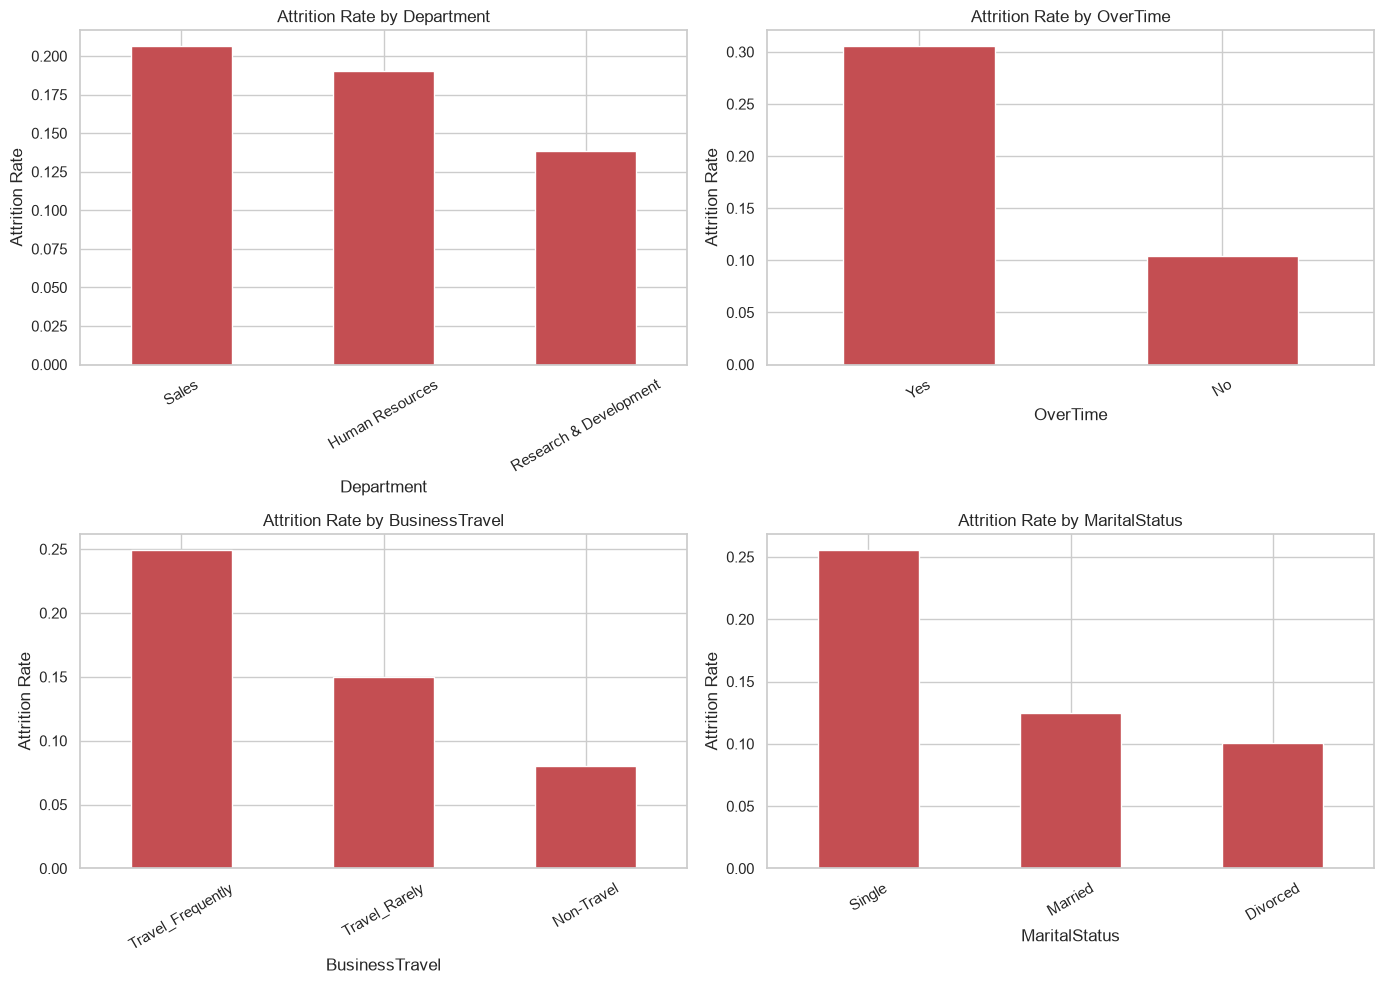

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, ['Department', 'OverTime', 'BusinessTravel', 'MaritalStatus']):
    rates = df.groupby(col)['Attrition_Flag'].mean().sort_values(ascending=False)
    rates.plot(kind='bar', ax=ax, color='#C44E52')
    ax.set_title(f'Attrition Rate by {col}')
    ax.set_ylabel('Attrition Rate')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Observation:** `OverTime = Yes` shows a markedly higher attrition rate than `OverTime = No` — this is likely to be one of the strongest predictors. Frequent travel and Sales are also associated with higher attrition.

## Attrition by Age Group and Income Range

Bucketing continuous features to make the relationship easier to read (and reusable for dashboard filters/charts).

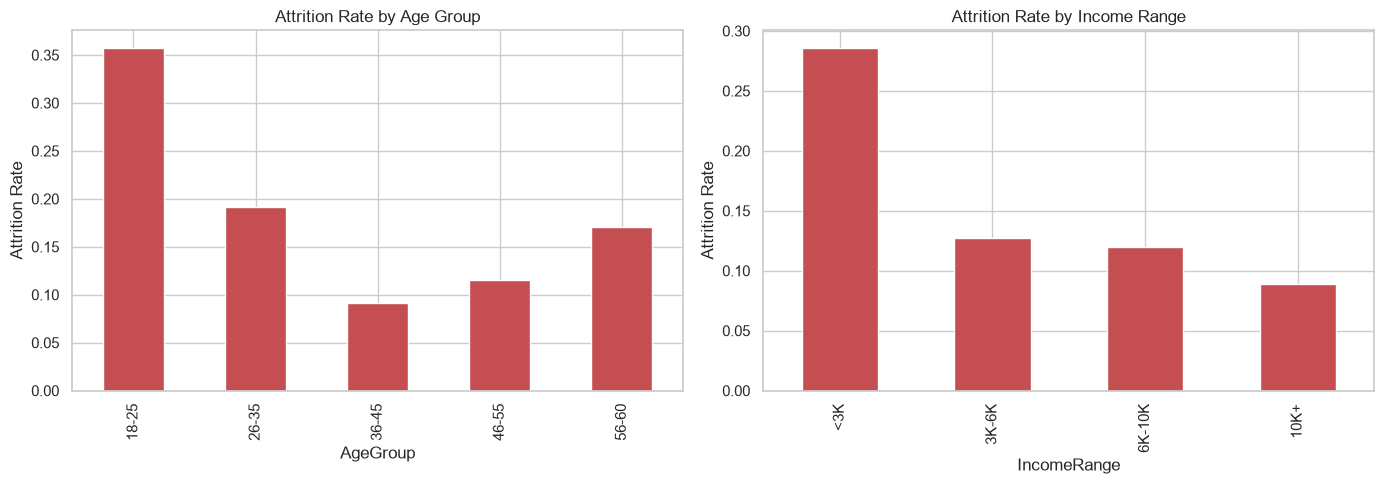

In [10]:
age_bins = [17, 25, 35, 45, 55, 61]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-60']
df['AgeGroup'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

income_bins = [0, 3000, 6000, 10000, 20000]
income_labels = ['<3K', '3K-6K', '6K-10K', '10K+']
df['IncomeRange'] = pd.cut(df['MonthlyIncome'], bins=income_bins, labels=income_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df.groupby('AgeGroup', observed=True)['Attrition_Flag'].mean().plot(kind='bar', ax=axes[0], color='#C44E52')
axes[0].set_title('Attrition Rate by Age Group')
axes[0].set_ylabel('Attrition Rate')

df.groupby('IncomeRange', observed=True)['Attrition_Flag'].mean().plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('Attrition Rate by Income Range')
axes[1].set_ylabel('Attrition Rate')

plt.tight_layout()
plt.show()

## Correlation Between Numerical Features and Attrition

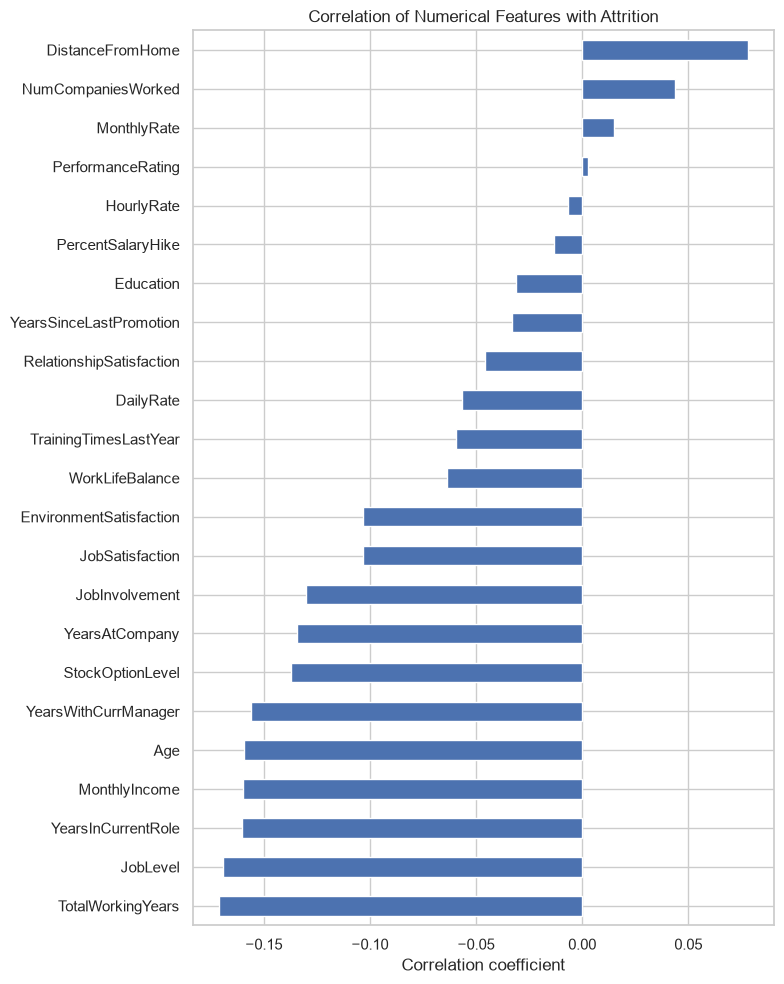

In [11]:
numerical_cols = df.select_dtypes(include=np.number).columns.drop(['Attrition_Flag', 'EmployeeNumber'], errors='ignore')
corr_with_target = df[numerical_cols].corrwith(df['Attrition_Flag']).sort_values()

plt.figure(figsize=(8, 10))
corr_with_target.plot(kind='barh', color='#4C72B0')
plt.title('Correlation of Numerical Features with Attrition')
plt.xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

## Full Correlation Heatmap

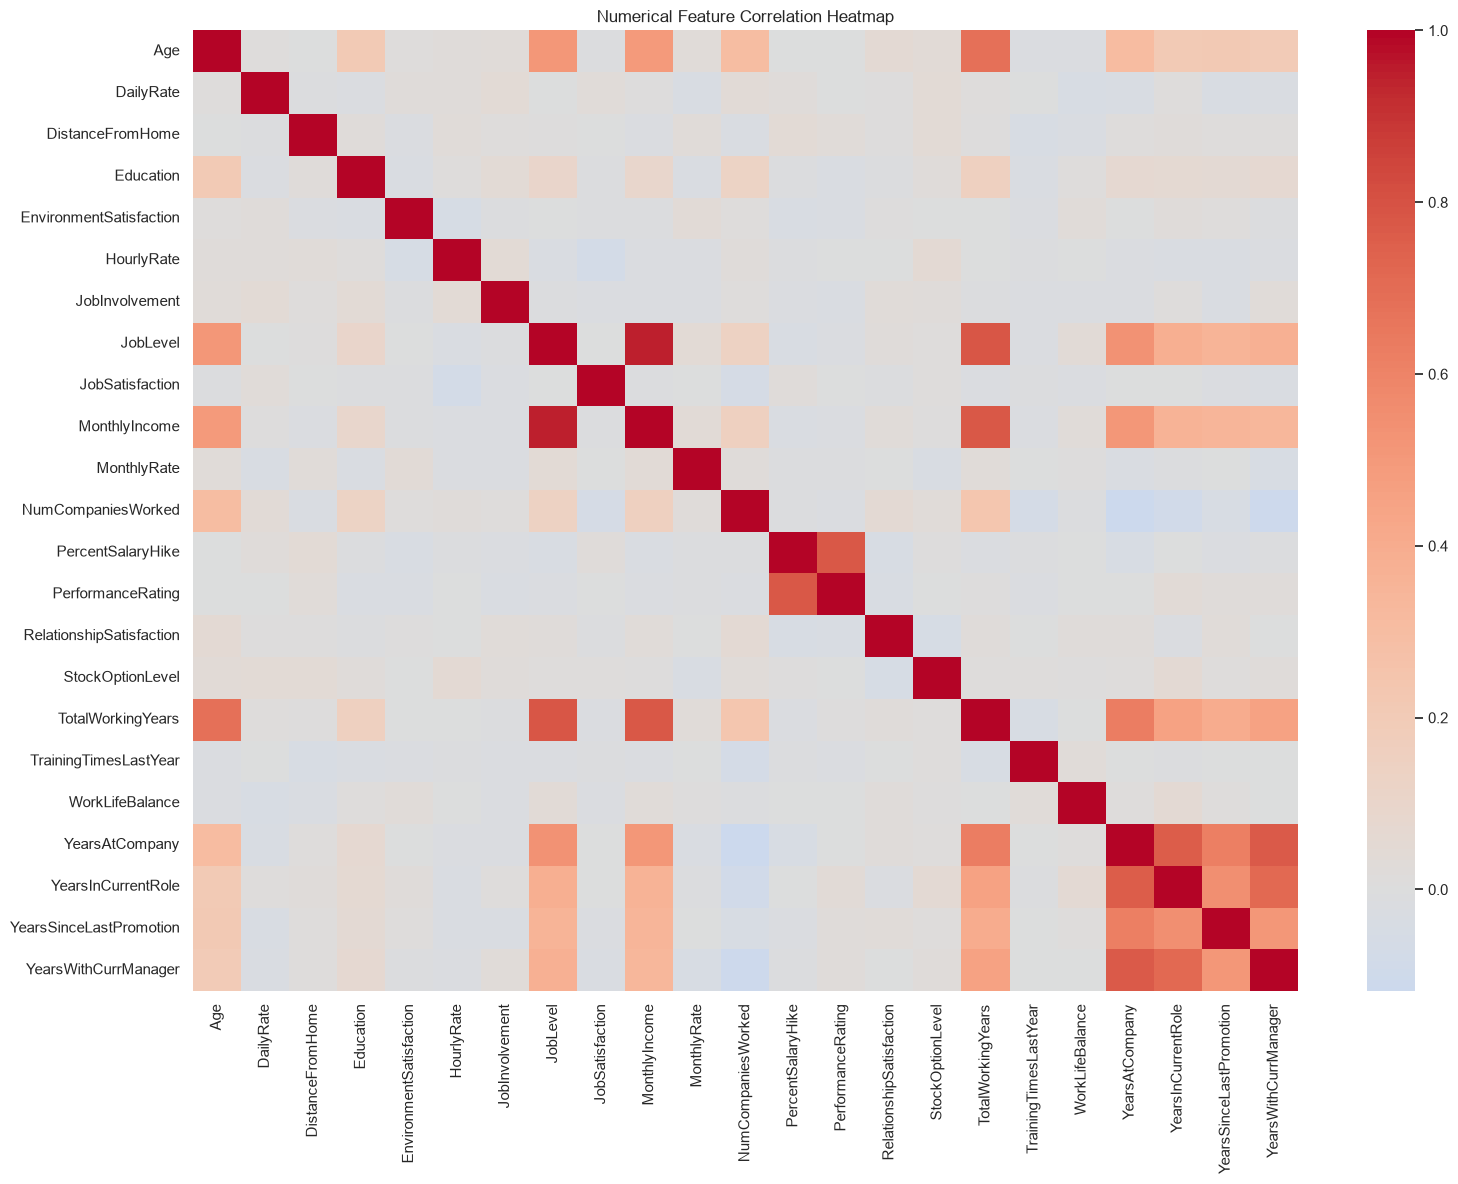

In [12]:
plt.figure(figsize=(16, 12))
sns.heatmap(df[numerical_cols].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Numerical Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Summary of Key EDA Findings

- Overall attrition rate is ~16.1% — a meaningfully imbalanced target; evaluation must go beyond accuracy (recall/F1/ROC-AUC/PR-AUC on the `Attrition=Yes` class).
- `OverTime`, `BusinessTravel` (frequent travelers), `MaritalStatus` (Single), and `JobRole`/`Department` (Sales roles) show elevated attrition rates — strong categorical predictors.
- Younger employees, lower income, fewer total working/company years, and lower satisfaction/work-life-balance scores are associated with higher attrition — strong numerical predictors.
- Several satisfaction-style ordinal columns (`JobSatisfaction`, `EnvironmentSatisfaction`, `WorkLifeBalance`) correlate with attrition and are worth keeping as numeric features rather than one-hot encoding.
- These findings directly inform the feature set and the dashboard's KPI/chart selection in later stages.